# European machine-learning comparison
Every model uses the same lag-1 inflation input. AR-HMM is fixed at the validated two-state specification.

In [1]:
from pathlib import Path
import json
import sys
import warnings
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
from statsmodels.tools.sm_exceptions import EstimationWarning, ConvergenceWarning

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'data').exists())
sys.path.insert(0, str(ROOT))
from modelling.models import fit_ar_hmm
warnings.filterwarnings('ignore', category=EstimationWarning)
warnings.filterwarnings('ignore', category=ConvergenceWarning)
data = pd.read_csv(ROOT / 'data/processed/europe/eu27_guardian_monthly_experiment.csv', parse_dates=['Date']).sort_values('Date')
results = json.loads((ROOT / 'data/processed/europe/eu27_guardian_results_2022_2025.json').read_text(encoding='utf-8'))

## Rolling validation
Models are tuned over 2017–2021 and evaluated once over 2022–2025. Target-month news is a month-end nowcast input.

In [2]:
folds = [
    ('2017–2018', '2016-12-01', '2017-01-01', '2018-12-01'),
    ('2019–2020', '2018-12-01', '2019-01-01', '2020-12-01'),
    ('2021', '2020-12-01', '2021-01-01', '2021-12-01'),
]
macro_lags = results['macro_lag_experiment']['selected_lags']
macro_features = [
    f"Unemployment_Change_Lag{macro_lags['unemployment']}",
    f"IP_Growth_MoM_Lag{macro_lags['industrial production']}",
    f"Energy_Inflation_MoM_Lag{macro_lags['energy HICP']}",
    f"PPI_Energy_Growth_MoM_Lag{macro_lags['energy PPI']}",
]
sentiment_features = ['News_Sentiment', 'Geopolitical_Risk', 'Energy_Risk', 'Supply_Chain_Risk']
feature_sets = {
    'Inflation lag 1': ['Inflation_MoM_Adjusted_Lag1'],
    'Lag 1 + macro': ['Inflation_MoM_Adjusted_Lag1', *macro_features],
    'Lag 1 + macro + sentiment': ['Inflation_MoM_Adjusted_Lag1', *macro_features, *sentiment_features],
}
grids = {
    'Linear AR': [{}],
    'Two-state AR-HMM': [{'n_states': 2}],
    'Random Forest': [
        {'n_estimators': 300, 'max_depth': 4, 'min_samples_leaf': 2, 'max_features': 0.7},
        {'n_estimators': 300, 'max_depth': None, 'min_samples_leaf': 4, 'max_features': 0.7},
        {'n_estimators': 300, 'max_depth': 6, 'min_samples_leaf': 6, 'max_features': 1.0},
    ],
    'Gradient Boosting': [
        {'n_estimators': 100, 'learning_rate': 0.03, 'max_depth': 2, 'min_samples_leaf': 4, 'subsample': 0.8},
        {'n_estimators': 100, 'learning_rate': 0.05, 'max_depth': 2, 'min_samples_leaf': 6, 'subsample': 0.8},
        {'n_estimators': 150, 'learning_rate': 0.03, 'max_depth': 1, 'min_samples_leaf': 4, 'subsample': 1.0},
    ],
}

def score(frame):
    return {'rmse': mean_squared_error(frame.Actual, frame.Forecast) ** 0.5,
            'mae': mean_absolute_error(frame.Actual, frame.Forecast)}

def prepare(training_end, test_end):
    training = data.loc[data.Date.le(training_end)].dropna(subset=['Inflation_MoM'])
    factors = training.groupby(training.Date.dt.month).Inflation_MoM.mean().to_dict()
    frame = data.loc[data.Date.le(test_end)].copy()
    frame['Seasonal_Factor'] = frame.Date.dt.month.map(factors)
    frame['Inflation_MoM_Adjusted'] = frame.Inflation_MoM - frame.Seasonal_Factor
    frame['Inflation_MoM_Adjusted_Lag1'] = frame.Inflation_MoM_Adjusted.shift(1)
    return frame, factors

def make_model(family, params):
    if family == 'Linear AR':
        return LinearRegression()
    if family == 'Random Forest':
        return RandomForestRegressor(**params, random_state=42, n_jobs=-1)
    return GradientBoostingRegressor(**params, random_state=42)

def fit_period(family, params, features, training_end, test_start, test_end):
    frame, factors = prepare(training_end, test_end)
    scale_sample = frame.loc[frame.Date.le(training_end), features]
    center = scale_sample.mean()
    scale = scale_sample.std().replace(0, 1)
    frame[features] = (frame[features] - center) / scale
    if family == 'Two-state AR-HMM':
        fitted = fit_ar_hmm(frame, features=features, name=family,
                            target='Inflation_MoM_Adjusted', test_start=test_start,
                            n_states=2, maxiter=2000, search_reps=30)
        output = fitted.forecasts.copy()
        seasonal = output.Date.dt.month.map(factors).to_numpy()
        output['Actual'] += seasonal
        output['Forecast'] += seasonal
        return fitted, output, fitted.parameters['converged']
    required = ['Inflation_MoM_Adjusted', *features]
    train = frame.loc[frame.Date.le(training_end)].dropna(subset=required)
    test = frame.loc[frame.Date.between(test_start, test_end)].dropna(subset=required)
    model = make_model(family, params).fit(train[features], train.Inflation_MoM_Adjusted)
    forecast = model.predict(test[features]) + test.Seasonal_Factor.to_numpy()
    output = pd.DataFrame({'Date': test.Date, 'Actual': test.Inflation_MoM, 'Forecast': forecast})
    return model, output, True

In [3]:
validation_runs = []
for information_set, features in feature_sets.items():
    for family, candidates in grids.items():
        for params in candidates:
            forecasts, converged = [], True
            for _, training_end, test_start, test_end in folds:
                _, fold_forecast, fit_converged = fit_period(
                    family, params, features, training_end, test_start, test_end)
                forecasts.append(fold_forecast)
                converged = converged and fit_converged
            metric = score(pd.concat(forecasts, ignore_index=True))
            validation_runs.append({'information': information_set, 'family': family,
                                    'params': params, 'converged': converged, **metric})
validation_grid = pd.DataFrame(validation_runs)
selected = (validation_grid.loc[validation_grid.converged].sort_values('rmse')
            .groupby(['information', 'family'], as_index=False).first())
display(selected[['information', 'family', 'rmse', 'mae']].sort_values(['information', 'rmse']).round(4))

,information,family,rmse,mae
1,Inflation lag 1,Linear AR,0.2414,0.1613
3,Inflation lag 1,Two-state AR-HMM,0.2416,0.1610
0,Inflation lag 1,Gradient Boosting,0.2441,0.1658
2,Inflation lag 1,Random Forest,0.2515,0.1781
5,Lag 1 + macro,Linear AR,0.2357,0.1569
4,Lag 1 + macro,Gradient Boosting,0.2470,0.1677
6,Lag 1 + macro,Random Forest,0.2533,0.1747
7,Lag 1 + macro,Two-state AR-HMM,0.2742,0.1930
9,Lag 1 + macro + sentiment,Linear AR,0.2356,0.1532
11,Lag 1 + macro + sentiment,Two-state AR-HMM,0.2432,0.1727


## Final test

In [4]:
final_results = []
for row in selected.itertuples(index=False):
    estimator, forecast, converged = fit_period(
        row.family, row.params, feature_sets[row.information],
        '2021-12-01', '2022-01-01', '2025-12-01')
    overall = score(forecast)
    in_2022 = score(forecast.loc[forecast.Date.dt.year.eq(2022)])
    later = score(forecast.loc[forecast.Date.dt.year.ge(2023)])
    final_results.append({'information': row.information, 'family': row.family,
                          'Validation RMSE': row.rmse, 'RMSE 2022–2025': overall['rmse'],
                          'MAE 2022–2025': overall['mae'], 'RMSE 2022': in_2022['rmse'],
                          'RMSE 2023–2025': later['rmse'], 'converged': converged,
                          'estimator': estimator, 'forecast': forecast})
final_table = pd.DataFrame(final_results)
display(final_table.drop(columns=['estimator', 'forecast'])
        .sort_values(['information', 'RMSE 2022–2025']).round(4))

# Preserve the exact predictions used for inference; tests never refit models.
benchmark_dir = ROOT / 'data/processed/europe/ml_benchmarks'
benchmark_dir.mkdir(parents=True, exist_ok=True)
benchmark_forecasts = pd.concat([
    row.forecast[['Date', 'Actual', 'Forecast']].assign(
        information=row.information, family=row.family)
    for row in final_table.itertuples(index=False)
], ignore_index=True)
benchmark_forecasts.to_csv(benchmark_dir / 'forecasts.csv', index=False)
final_table.drop(columns=['estimator', 'forecast']).to_csv(benchmark_dir / 'metrics.csv', index=False)
(benchmark_dir / 'model_selection.json').write_text(json.dumps({
    'selection_period': '2017-2021', 'training_end': '2021-12-01',
    'test_period': '2022-2025', 'feature_sets': feature_sets,
    'selected_models': selected.to_dict('records'),
    'ar_hmm_fit': {'n_states': 2, 'maxiter': 2000, 'search_reps': 30, 'random_seed': 42},
}, indent=2, allow_nan=False) + '\n', encoding='utf-8')


,information,family,Validation RMSE,RMSE 2022–2025,MAE 2022–2025,RMSE 2022,RMSE 2023–2025,converged
1,Inflation lag 1,Linear AR,0.2414,0.4331,0.3230,0.6872,0.3044,True
3,Inflation lag 1,Two-state AR-HMM,0.2416,0.4331,0.3263,0.6820,0.3083,True
2,Inflation lag 1,Random Forest,0.2515,0.4466,0.3322,0.7193,0.3057,True
0,Inflation lag 1,Gradient Boosting,0.2441,0.4523,0.3400,0.7302,0.3084,True
7,Lag 1 + macro,Two-state AR-HMM,0.2742,0.4460,0.3479,0.6686,0.3409,True
5,Lag 1 + macro,Linear AR,0.2357,0.4585,0.3529,0.7051,0.3385,True
6,Lag 1 + macro,Random Forest,0.2533,0.4622,0.3503,0.7323,0.3257,True
4,Lag 1 + macro,Gradient Boosting,0.2470,0.4637,0.3541,0.7385,0.3238,True
11,Lag 1 + macro + sentiment,Two-state AR-HMM,0.2432,0.3959,0.3059,0.5960,0.3009,True
9,Lag 1 + macro + sentiment,Linear AR,0.2356,0.4556,0.3402,0.7299,0.3149,True


## Statistical significance of the macro + news improvement

Baseline,Months,Baseline RMSE,Macro + news RMSE,RMSE improvement (%),95% CI lower (%),95% CI upper (%),DM statistic,DM p-value (two-sided),DM p-value (Holm),"Significant improvement (5%, Holm)"
Inflation lag 1,48,0.4331,0.3959,8.6014,0.6745,14.1951,1.6596,0.1037,0.1037,False
Lag 1 + macro,48,0.4460,0.3959,11.2471,4.6869,18.3203,2.7210,0.0091,0.0182,True


Versus Inflation lag 1: RMSE reduction 8.60%, 95% CI [0.67%, 14.20%], two-sided Holm p = 0.1037; insufficient evidence of improvement at the 5% level.
Versus Lag 1 + macro: RMSE reduction 11.25%, 95% CI [4.69%, 18.32%], two-sided Holm p = 0.0182; statistically significant improvement.


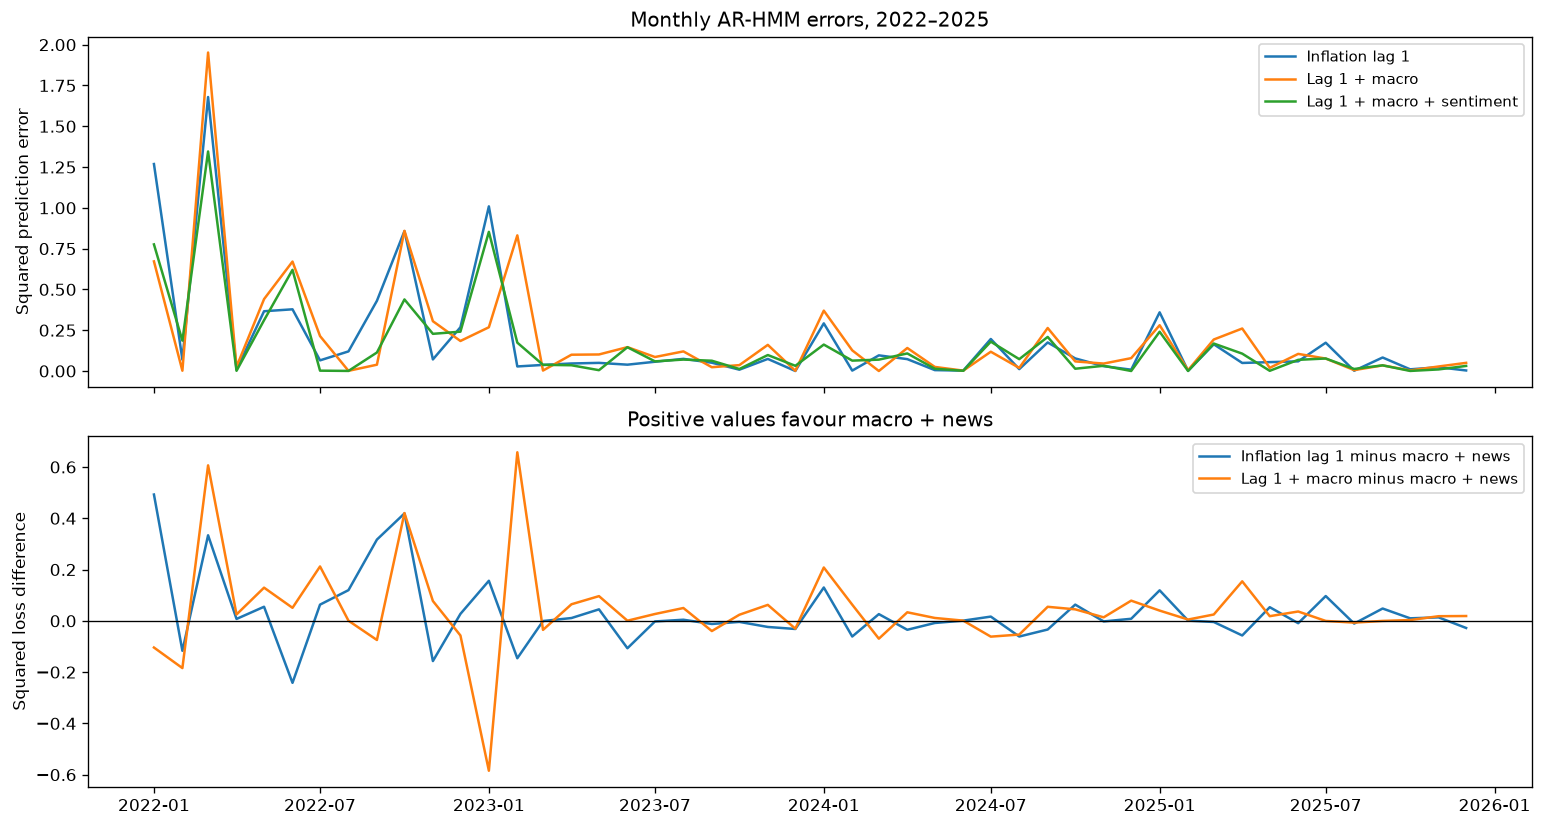

In [ ]:
from modelling.forecast_significance import analyse_europe_benchmarks, significance_table

significance = analyse_europe_benchmarks(benchmark_forecasts, output_dir=benchmark_dir)
display(significance_table(significance).round(4))
for comparison in significance['comparisons']:
    p = comparison['dm']['pvalue_holm']
    conclusion = ('statistically significant improvement' if comparison['dm']['significant_improvement_holm']
                  else 'insufficient evidence of improvement at the 5% level')
    p_text = f'{p:.4f}' if p is not None else 'undefined'
    ci = comparison['bootstrap']['rmse_improvement_pct_ci']
    ci_text = f'[{ci[0]:.2f}%, {ci[1]:.2f}%]' if ci is not None else 'undefined'
    print(f"Versus {comparison['baseline_information']}: "
          f"RMSE reduction {comparison['rmse_improvement_pct']:.2f}%, "
          f"95% CI {ci_text}, two-sided Holm p = {p_text}; {conclusion}.")

# Inspect the paired loss series on which inference depends.
ar_hmm_predictions = benchmark_forecasts.loc[benchmark_forecasts.family.eq('Two-state AR-HMM')]
loss_series = {}
fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
for information, frame in ar_hmm_predictions.groupby('information'):
    frame = frame.sort_values('Date').set_index('Date')
    loss_series[information] = (frame.Actual - frame.Forecast) ** 2
    axes[0].plot(frame.index, loss_series[information], label=information)
for baseline_information in ['Inflation lag 1', 'Lag 1 + macro']:
    differences = loss_series[baseline_information] - loss_series['Lag 1 + macro + sentiment']
    axes[1].plot(differences.index, differences, label=f'{baseline_information} minus macro + news')
axes[0].set(ylabel='Squared prediction error', title='Monthly AR-HMM errors, 2022–2025')
axes[1].axhline(0, color='black', linewidth=0.8)
axes[1].set(ylabel='Squared loss difference', xlabel='', title='Positive values favour macro + news')
for ax in axes:
    ax.legend(fontsize=9)
plt.tight_layout()
plt.show()


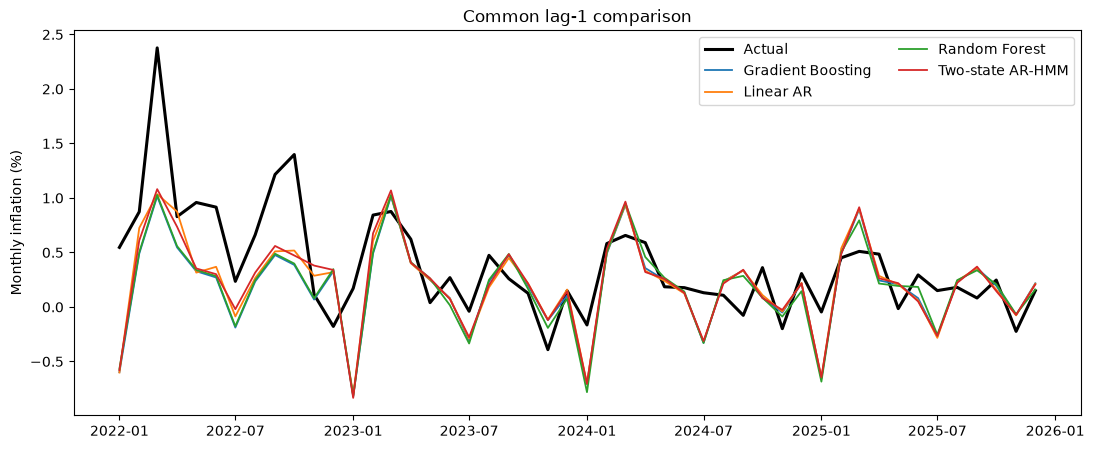

In [5]:
baseline = final_table.loc[final_table.information.eq('Inflation lag 1')]
actual = baseline.iloc[0].forecast
fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(actual.Date, actual.Actual, color='black', linewidth=2.2, label='Actual')
for row in baseline.itertuples(index=False):
    ax.plot(row.forecast.Date, row.forecast.Forecast, linewidth=1.3, label=row.family)
ax.set(title='Common lag-1 comparison', ylabel='Monthly inflation (%)', xlabel='')
ax.legend(ncol=2)
plt.show()